# TravelTide — Exploratory Data Analysis

Explore the selected users’ behavior and assess data quality as a basis
for customer segmentation and reward recommendations.

Das Verhalten der ausgewählten Nutzer untersuchen und die Datenqualität
als Grundlage für Kundengruppen und Reward-Empfehlungen prüfen.

## 1. Packages / Pakete

Import packages for data analysis, visualization and later clustering.
Display the Python environment used by this notebook.

Pakete für Datenanalyse, Visualisierung und späteres Clustering importieren.
Die verwendete Python-Umgebung anzeigen.

In [38]:
# packages for data analysis, visualization and later clustering
# pakete für datenanalyse, visualisierung und späteres clustering

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import airportsdata

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import HTML, display

# shared color palette and chart defaults
# gemeinsame farbpalette und standardgestaltung der diagramme
COLORS = {
    "blue": "#93B4DB",
    "lavender": "#B5ACD9",
    "mint": "#9BCBC3",
    "ice": "#B9DDE8",
    "highlight": "#8D83BA",
    "text": "#334155",
    "background": "#F5F7FB",
}

PALETTE = [
    COLORS["blue"],
    COLORS["lavender"],
    COLORS["mint"],
    COLORS["ice"],
]

sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    rc={
        "figure.facecolor": COLORS["background"],
        "axes.facecolor": COLORS["background"],
        "text.color": COLORS["text"],
        "axes.labelcolor": COLORS["text"],
        "xtick.color": COLORS["text"],
        "ytick.color": COLORS["text"],
        "grid.color": "#DDE3EC",
        "axes.spines.top": False,
        "axes.spines.right": False,
    },
)

px.defaults.template = "plotly_white"
px.defaults.color_discrete_sequence = PALETTE


# shared pastel styling for overview tables
# gemeinsame pastellgestaltung für übersichtstabellen
def style_overview(df, title, formats=None):
    return (
        df.style
        .hide(axis="index")
        .set_caption(title)
        .format(formats or {})
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("color", COLORS["ice"]),
                    ("font-size", "18px"),
                    ("font-weight", "700"),
                    ("text-align", "left"),
                    ("padding", "12px 0"),
                ],
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", COLORS["blue"]),
                    ("color", COLORS["text"]),
                    ("padding", "10px 14px"),
                    ("text-align", "left"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("background-color", COLORS["background"]),
                    ("color", COLORS["text"]),
                    ("padding", "8px 14px"),
                    ("border-bottom", "1px solid #DDE3EC"),
                ],
            },
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("font-family", "Segoe UI, sans-serif"),
                ],
            },
        ])
    )

print("Python environment / Python-Umgebung:", sys.executable)

Python environment / Python-Umgebung: c:\Users\mpero\Desktop\GitHub\TravelTide\.venv\Scripts\python.exe


## 2. Load and validate data / Daten laden und prüfen

### 2.1 Load sessions / Sessions laden

Determine the project folder and load the local session export.
Check the number of sessions and distinct users.

Den Projektordner bestimmen und den lokalen Session-Export laden.
Die Anzahl der Sessions und unterschiedlichen Nutzer prüfen.

In [39]:
# locate the project folder from either the root or notebooks directory
# projektordner vom hauptordner oder notebook-ordner aus bestimmen
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# load the local session export
# lokalen session-export laden
sessions = pd.read_csv(project_root / "data" / "raw" / "sessions.csv")

print("Sessions:", len(sessions))
print("Users / Nutzer:", sessions["user_id"].nunique())

Sessions: 49211
Users / Nutzer: 5998


### 2.2 Load remaining tables and validate exports
### Weitere Tabellen laden und Exporte prüfen

Load user, flight and hotel data. Compare all four table sizes with
the SQL results and check primary keys for missing and duplicate values.

Nutzer-, Flug- und Hoteldaten laden. Die Größe aller vier Tabellen mit
den SQL-Ergebnissen vergleichen und Primärschlüssel auf fehlende
und doppelte Werte prüfen.

In [40]:
# load the remaining local exports
# weitere lokale exportdateien laden
users = pd.read_csv(project_root / "data" / "raw" / "users.csv")
flights = pd.read_csv(project_root / "data" / "raw" / "flights.csv")
hotels = pd.read_csv(project_root / "data" / "raw" / "hotels.csv")

# compare exported row counts with SQL results and check primary keys
# exportierte zeilenzahlen mit SQL-ergebnissen vergleichen und schlüssel prüfen
tables = {
    "users": (users, "user_id", 5998),
    "sessions": (sessions, "session_id", 49211),
    "flights": (flights, "trip_id", 13717),
    "hotels": (hotels, "trip_id", 14313),
}

export_checks = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "expected_rows": expected,
        "row_count_matches": len(df) == expected,
        "missing_keys": df[key].isna().sum(),
        "duplicate_keys": df[key].duplicated().sum(),
    }
    for name, (df, key, expected) in tables.items()
])

# highlight validation results while keeping the shared table design
# prüfergebnisse hervorheben und gemeinsame tabellengestaltung verwenden
def highlight_check(value, expected):
    passed = value == expected
    background = "#DDEFEA" if passed else "#F5DFE3"
    color = "#24594D" if passed else "#8B3045"

    return (
        f"background-color: {background}; "
        f"color: {color}; font-weight: 600;"
    )


styled_checks = (
    style_overview(
        export_checks,
        "Export validation",
        {
            "rows": "{:,.0f}",
            "expected_rows": "{:,.0f}",
            "row_count_matches": (
                lambda value: "✓ OK" if value else "✗ Mismatch"
            ),
            "missing_keys": "{:,.0f}",
            "duplicate_keys": "{:,.0f}",
        },
    )
    .map(
        lambda value: highlight_check(value, True),
        subset=["row_count_matches"],
    )
    .map(
        lambda value: highlight_check(value, 0),
        subset=["missing_keys", "duplicate_keys"],
    )
)

display(styled_checks)

table,rows,expected_rows,row_count_matches,missing_keys,duplicate_keys
users,"5,998","5,998",✓ OK,0,0
sessions,"49,211","49,211",✓ OK,0,0
flights,"13,717","13,717",✓ OK,0,0
hotels,"14,313","14,313",✓ OK,0,0


### Findings / Erkenntnisse

All four exported row counts match the SQL results.
The primary keys contain no missing or duplicate values.

Alle vier exportierten Zeilenzahlen stimmen mit den SQL-Ergebnissen überein.
Die Primärschlüssel enthalten keine fehlenden oder doppelten Werte.

In [41]:
# create working copies and preserve the imported source data
# arbeitskopien erstellen und eingelesene ausgangsdaten erhalten
users_work = users.copy()
sessions_work = sessions.copy()
flights_work = flights.copy()
hotels_work = hotels.copy()

working_tables = {
    "users": users_work,
    "sessions": sessions_work,
    "flights": flights_work,
    "hotels": hotels_work,
}

## 3. Data types and missing values
## Datentypen und fehlende Werte

Inspect the imported data types and missing values in each column.
CSV files do not preserve database types, so dates and other fields
may require explicit conversion.

Die eingelesenen Datentypen und fehlenden Werte jeder Spalte prüfen.
CSV-Dateien bewahren die Datenbanktypen nicht. Datumsfelder und andere
Spalten müssen deshalb gegebenenfalls ausdrücklich umgewandelt werden.

In [42]:
# prepare an overview for each table without changing its values
# übersichten erstellen, ohne die tabellenwerte zu verändern
overview_tiles = []

for name, df in working_tables.items():
    overview = pd.DataFrame({
        "column": df.columns,
        "dtype": df.dtypes.astype(str).to_numpy(),
        "missing": df.isna().sum().to_numpy(),
        "missing_pct": df.isna().mean().mul(100).to_numpy(),
    })

    styled = style_overview(
        overview,
        f"{name} — Data overview",
        {
            "missing": "{:,.0f}",
            "missing_pct": "{:.2f}%",
        },
    )

    overview_tiles.append(
        '<div style="min-width: 0; overflow-x: auto; '
        'padding: 12px; border: 1px solid #64748B; '
        'border-radius: 12px;">'
        + styled.to_html()
        + "</div>"
    )

# display four tables in a two-by-two grid
# vier tabellen in einem zwei-mal-zwei-raster anzeigen
display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(2, minmax(0, 1fr)); '
    'gap: 20px; align-items: start;">'
    + "".join(overview_tiles)
    + "</div>"
))

column,dtype,missing,missing_pct
user_id,int64,0,0.00%
birthdate,str,0,0.00%
gender,str,0,0.00%
married,bool,0,0.00%
has_children,bool,0,0.00%
home_country,str,0,0.00%
home_city,str,0,0.00%
home_airport,str,0,0.00%
home_airport_lat,float64,0,0.00%
home_airport_lon,float64,0,0.00%


### 3.1 Convert user dates / Nutzerdaten in Datumswerte umwandeln

Convert birthdate and sign_up_date to datetime values.
Count any previously non-missing values that cannot be parsed.

birthdate und sign_up_date in Datumswerte umwandeln.
Zählen, wie viele zuvor vorhandene Werte nicht gelesen werden können.

In [43]:
# convert date columns and check for parsing failures
# datumsspalten umwandeln und auf nicht lesbare werte prüfen
date_checks = []

for column in ["birthdate", "sign_up_date"]:
    original = users_work[column].copy()
    converted = pd.to_datetime(original, errors="coerce")

    date_checks.append({
        "column": column,
        "dtype_before": str(original.dtype),
        "dtype_after": str(converted.dtype),
        "parsing_failures": (
            original.notna() & converted.isna()
        ).sum(),
    })

    users_work[column] = converted

display(style_overview(
    pd.DataFrame(date_checks),
    "users — Date conversion",
    {"parsing_failures": "{:,.0f}"},
))

column,dtype_before,dtype_after,parsing_failures
birthdate,str,datetime64[us],0
sign_up_date,str,datetime64[us],0


### 3.2 Validate user categories / Nutzerkategorien prüfen

Inspect gender, marital status and whether users have children.
has_children indicates whether children are present, not their number.

Geschlecht, Familienstand und die Angabe zu Kindern untersuchen.
has_children zeigt, ob Nutzer Kinder haben, nicht wie viele.

value,users,share_pct
F,"5,292",88.23%
M,695,11.59%
O,11,0.18%
value,users,share_pct
False,"3,356",55.95%
True,"2,642",44.05%
value,users,share_pct
False,"4,040",67.36%
True,"1,958",32.64%


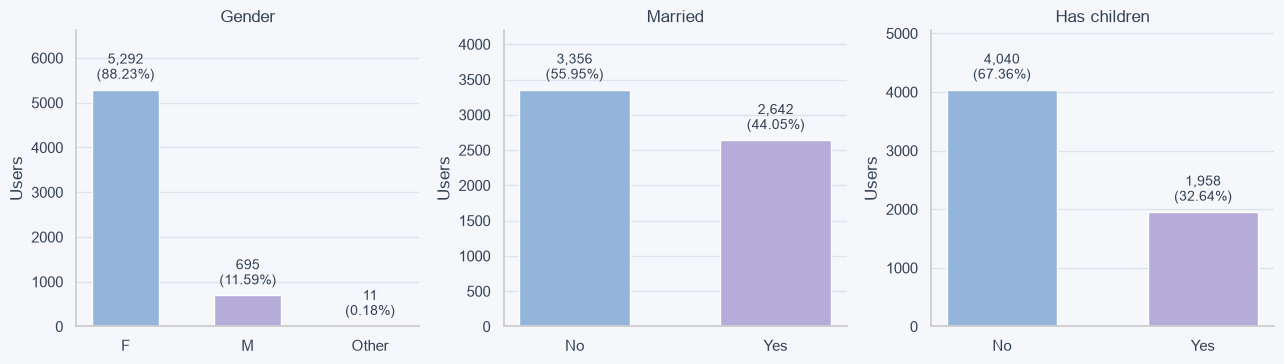

In [44]:
# prepare category tables and charts
# kategorietabellen und diagramme vorbereiten
chart_settings = [
    ("gender", ["F", "M", "O"], ["F", "M", "Other"], "Gender"),
    ("married", [False, True], ["No", "Yes"], "Married"),
    ("has_children", [False, True], ["No", "Yes"], "Has children"),
]

html_tables = []

for column, order, labels, title in chart_settings:
    counts = (
        users_work[column]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="users")
    )
    counts["share_pct"] = counts["users"] / len(users_work) * 100

    styled = style_overview(
        counts,
        title,
        {
            "users": "{:,.0f}",
            "share_pct": "{:.2f}%",
        },
    )

    # apply the shared pastel palette to table headers
    # gemeinsame pastellpalette für tabellenüberschriften verwenden
    styled = styled.set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["blue"]),
                ("color", COLORS["text"]),
            ],
        },
      {
    "selector": "caption",
    "props": [
        ("color", COLORS["ice"]),
        ("font-size", "18px"),
        ("font-weight", "700"),
    ],
},
        {
            "selector": "td",
            "props": [
                ("background-color", COLORS["background"]),
                ("color", COLORS["text"]),
            ],
        },
    ], overwrite=False)

    html_tables.append(
        f'<div style="min-width: 0;">{styled.to_html()}</div>'
    )

# display three tables in one row
# drei tabellen in einer zeile anzeigen
display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(3, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(html_tables)
    + "</div>"
))

# display three charts underneath in the same order
# drei diagramme darunter in derselben reihenfolge anzeigen
fig, axes = plt.subplots(ncols=3, figsize=(13, 3.8))

for ax, (column, order, labels, title) in zip(axes, chart_settings):
    counts = (
        users_work[column]
        .value_counts()
        .reindex(order, fill_value=0)
    )
    percentages = counts / len(users_work) * 100

    bars = ax.bar(
        labels,
        counts.to_numpy(),
        color=PALETTE[:len(order)],
        width=0.55,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{count:,.0f}\n({percentage:.2f}%)"
            for count, percentage in zip(counts, percentages)
        ],
        padding=5,
        fontsize=10,
    )

    ax.set(
        title=title,
        ylabel="Users",
        ylim=(0, max(counts.max(), 1) * 1.25),
    )
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### 3.3 Validate text values / Textwerte prüfen

Check all user text columns for empty values, surrounding whitespace
and variants that differ only in capitalization or whitespace.

Alle Textspalten auf leere Werte, äußere Leerzeichen und Varianten prüfen,
die sich nur durch Groß-/Kleinschreibung oder Leerzeichen unterscheiden.

In [45]:
# inspect text columns without changing the working data
# textspalten prüfen, ohne die arbeitsdaten zu verändern
text_checks = []
text_variants = {}

for column in users_work.select_dtypes(
    include=["object", "string", "str"]
).columns:
    values = users_work[column].astype("string")
    stripped = values.str.strip()
    normalized = stripped.str.casefold()

    variants = pd.DataFrame({
        "original": values,
        "normalized": normalized,
    }).dropna().drop_duplicates()

    variant_counts = variants.groupby("normalized")["original"].nunique()
    variant_groups = variant_counts[variant_counts > 1].index

    text_checks.append({
        "column": column,
        "unique_values": values.nunique(),
        "blank_values": stripped.eq("").sum(),
        "surrounding_whitespace": values.ne(stripped).sum(),
        "variant_groups": len(variant_groups),
    })

    text_variants[column] = variants[
        variants["normalized"].isin(variant_groups)
    ].sort_values(["normalized", "original"])

display(style_overview(
    pd.DataFrame(text_checks),
    "users — Text validation",
    {
        "unique_values": "{:,.0f}",
        "blank_values": "{:,.0f}",
        "surrounding_whitespace": "{:,.0f}",
        "variant_groups": "{:,.0f}",
    },
))

column,unique_values,blank_values,surrounding_whitespace,variant_groups
gender,3,0,0,0
home_country,2,0,0,0
home_city,105,0,0,0
home_airport,159,0,0,0


### Standardize countries and cities / Länder und Städte vereinheitlichen

Standardize country names to USA and Canada and apply title case
to city names. Preserve the original values in users.

Ländernamen auf USA und Canada vereinheitlichen und Stadtwörter
mit großen Anfangsbuchstaben darstellen. Die Originalwerte
bleiben in users erhalten.

In [46]:
# preserve values for the before-and-after comparison
# werte für den vorher-nachher-vergleich erhalten
location_before = users_work[
    ["home_country", "home_city"]
].copy()

# standardize known country names
# bekannte ländernamen vereinheitlichen
country_text = (
    users_work["home_country"]
    .astype("string")
    .str.strip()
)

country_mapping = {
    "usa": "USA",
    "canada": "Canada",
}

users_work["home_country"] = (
    country_text.str.casefold()
    .map(country_mapping)
    .fillna(country_text)
)

# capitalize each city word
# jedes wort der stadtnamen mit großbuchstaben beginnen
users_work["home_city"] = (
    users_work["home_city"]
    .astype("string")
    .str.strip()
    .str.title()
)

# display changed spellings side by side
# geänderte schreibweisen nebeneinander anzeigen
html_tables = []

for column in ["home_country", "home_city"]:
    comparison = pd.DataFrame({
        "before": location_before[column],
        "after": users_work[column],
    })

    changed = comparison["before"].ne(
        comparison["after"]
    ).fillna(False)

    changes = (
        comparison.loc[changed]
        .value_counts()
        .reset_index(name="affected_users")
    )

    html_tables.append(
        '<div style="min-width: 0; overflow-x: auto;">'
        + style_overview(
            changes,
            f"{column} — Spelling changes",
            {"affected_users": "{:,.0f}"},
        ).to_html()
        + "</div>"
    )

display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(2, minmax(0, 1fr)); '
    'gap: 24px; align-items: start;">'
    + "".join(html_tables)
    + "</div>"
))

before,after,affected_users
usa,USA,"4,991"
canada,Canada,"1,007"
before,after,affected_users
new york,New York,680
los angeles,Los Angeles,325
toronto,Toronto,225
chicago,Chicago,195
houston,Houston,185
montreal,Montreal,166
san antonio,San Antonio,132


### Enrich home-airport information / Heimatflughäfen ergänzen

Use airportsdata to add airport names, cities and country codes.
Check unmatched airport codes before comparing cities.
The reference data reflects current information, not necessarily 2023.

Mit airportsdata Flughafennamen, Städte und Ländercodes ergänzen.
Nicht zugeordnete Flughafencodes vor dem Städtevergleich prüfen.
Die Referenzdaten entsprechen dem aktuellen Stand, nicht zwingend 2023.

In [54]:
# load airport reference data indexed by IATA code
# flughafenreferenzdaten nach IATA-code laden
airport_reference = pd.DataFrame.from_dict(
    airportsdata.load("IATA"),
    orient="index",
)

# normalize lookup keys without replacing the original airport codes
# suchschlüssel vereinheitlichen, ohne originalcodes zu ersetzen
airport_keys = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# add reference fields to the working copy
# referenzfelder zur arbeitskopie hinzufügen
for source, target in [
    ("name", "home_airport_name"),
    ("city", "home_airport_city"),
    ("country", "home_airport_country_code"),
]:
    users_work[target] = (
        airport_keys
        .map(airport_reference[source])
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# check lookup coverage separately from field completeness
# zuordnungsquote getrennt von der feldvollständigkeit prüfen
matched = airport_keys.isin(airport_reference.index)

lookup_summary = pd.DataFrame({
    "check": [
        "Total users",
        "Users with matched airport code",
        "Users with unmatched airport code",
        "Users without airport name",
        "Users without airport city",
    ],
    "users": [
        len(users_work),
        matched.sum(),
        (~matched).sum(),
        users_work["home_airport_name"].isna().sum(),
        users_work["home_airport_city"].isna().sum(),
    ],
})

unmatched_codes = (
    airport_keys.loc[~matched]
    .value_counts(dropna=False)
    .rename_axis("airport_code")
    .reset_index(name="users")
)

# display validation tables side by side
# prüftabellen nebeneinander anzeigen
table_specs = [
    (lookup_summary, "Airport lookup — Coverage"),
    (unmatched_codes, "Airport lookup — Unmatched codes"),
]

display(HTML(
    '<div style="display: flex; gap: 24px; '
    'align-items: flex-start; flex-wrap: wrap;">'
    + "".join(
        "<div>"
        + style_overview(
            df, title, {"users": "{:,.0f}"}
        ).to_html()
        + "</div>"
        for df, title in table_specs
    )
    + "</div>"
))

display(style_overview(
    users_work[
        ["home_airport", "home_airport_name", "home_airport_city"]
    ].drop_duplicates().head(10),
    "Airport lookup — Preview",
))

check,users
Total users,"5,998"
Users with matched airport code,"5,752"
Users with unmatched airport code,246
Users without airport name,246
Users without airport city,270
airport_code,users
YKZ,66
YZD,53
YED,33
YXD,28


home_airport,home_airport_name,home_airport_city
LGA,Laguardia Airport,New York
MCI,Kansas City International Airport,Kansas City
TCM,Mcchord Field (Joint Base Lewis-Mcchord) Airport,Tacoma
BOS,General Edward Lawrence Logan International Airport,Boston
TNT,Dade-Collier Training And Transition Airport,Miami
LAX,Los Angeles International Airport,Los Angeles
SNA,John Wayne/Orange County Airport,Santa Ana
BIF,Biggs Army Air Field (Fort Bliss) Airport,Fort Bliss/El Paso/
AUS,Austin-Bergstrom International Airport,Austin
BHM,Birmingham-Shuttlesworth International Airport,Birmingham


### Inspect potentially military airports
### Möglicherweise militärische Flughäfen untersuchen

Search airport names for military-related terms and inspect linked
flight records and booking indicators in the current analysis group.
This is an exploratory check using data not yet fully validated.

Flughafennamen nach militärischen Begriffen durchsuchen und zugehörige
Flugdatensätze sowie Buchungsindikatoren der aktuellen Analysegruppe prüfen.
Dies ist eine explorative Prüfung noch nicht vollständig validierter Daten.

In [55]:
# inspect both home airports and flight origins
# sowohl heimatflughäfen als auch abflughäfen untersuchen
home_codes = (
    users_work["home_airport"]
    .astype("string").str.strip().str.upper()
)
origin_codes = (
    flights_work["origin_airport"]
    .astype("string").str.strip().str.upper()
)

airport_codes = pd.Index(
    pd.concat([home_codes, origin_codes]).dropna().unique()
)

airport_candidates = pd.DataFrame({
    "airport_code": airport_codes,
})

airport_candidates["airport_name"] = (
    airport_candidates["airport_code"]
    .map(airport_reference["name"])
)

# name-based screening, not a confirmed classification
# namensbasierte suche, keine bestätigte klassifizierung
military_pattern = (
    r"\b(?:army|navy|naval|air\s*force|airforce|military|"
    r"afb|aaf|nas|air\s*base|joint\s*base|marine\s*corps|"
    r"rcaf|cfb)\b"
)

military_airports = airport_candidates.loc[
    airport_candidates["airport_name"].str.contains(
        military_pattern,
        case=False,
        regex=True,
        na=False,
    )
].copy()

# identify trips with an explicit flight-booking indicator
# reisen mit ausdrücklichem flugbuchungsindikator identifizieren
flight_booking_sessions = sessions_work.loc[
    sessions_work["flight_booked"].eq(True)
    & sessions_work["trip_id"].notna(),
    ["user_id", "trip_id"],
].drop_duplicates()

booking_trip_ids = flight_booking_sessions["trip_id"].unique()

results = []

for airport in military_airports.itertuples(index=False):
    origin_flights = flights_work.loc[
        origin_codes.eq(airport.airport_code).fillna(False)
    ]

    booked_origin_flights = origin_flights.loc[
        origin_flights["trip_id"].isin(booking_trip_ids)
    ]

    booking_users = flight_booking_sessions.loc[
        flight_booking_sessions["trip_id"].isin(
            booked_origin_flights["trip_id"]
        ),
        "user_id",
    ].nunique()

    results.append({
        "airport_code": airport.airport_code,
        "airport_name": airport.airport_name,
        "home_users": home_codes.eq(airport.airport_code).sum(),
        "origin_flight_records": len(origin_flights),
        "trips_with_booking_flag": (
            booked_origin_flights["trip_id"].nunique()
        ),
        "booking_users": booking_users,
    })

military_airport_check = pd.DataFrame(
    results,
    columns=[
        "airport_code",
        "airport_name",
        "home_users",
        "origin_flight_records",
        "trips_with_booking_flag",
        "booking_users",
    ],
).sort_values(
    ["trips_with_booking_flag", "airport_code"],
    ascending=[False, True],
)

display(style_overview(
    military_airport_check,
    "Potential military airports — Exploratory booking check",
    {
        "home_users": "{:,.0f}",
        "origin_flight_records": "{:,.0f}",
        "trips_with_booking_flag": "{:,.0f}",
        "booking_users": "{:,.0f}",
    },
))

airport_code,airport_name,home_users,origin_flight_records,trips_with_booking_flag,booking_users
LUF,Luke Afb Airport,60,134,134,50
RND,Randolph Afb Airport,46,126,126,42
NZY,North Island Nas (Halsey Field) Airport,50,113,113,42
BIF,Biggs Army Air Field (Fort Bliss) Airport,34,82,82,30
LSV,Nellis Afb Airport,25,64,64,22
DMA,Davis Monthan Afb Airport,22,63,63,22
OFF,Offutt Afb Airport,30,63,63,26
TIK,Tinker Afb Airport,24,63,63,22
TCM,Mcchord Field (Joint Base Lewis-Mcchord) Airport,21,40,40,20
MXF,Maxwell Afb Airport,23,37,37,18


**English:** Flight bookings in our analysis group reference all listed airports
with military-related names as departure airports.

**Deutsch:** Flugbuchungen unserer Analysegruppe verweisen auf alle aufgeführten
Flughäfen mit militärischen Namensbestandteilen als Abflughäfen.

In [56]:
# remove airport names after inspection; retain codes and cities
# flughafennamen nach der prüfung entfernen; codes und städte behalten
users_work.drop(
    columns=["home_airport_name"],
    errors="ignore",
    inplace=True,
)

### Complete researched airport cities / Recherchierte Flughafenstädte ergänzen

Fill missing airport cities using externally researched locations.
Require both the airport code and matching source coordinates.
Preserve the original codes, coordinates and users' home cities.

Fehlende Flughafenstädte anhand extern recherchierter Standorte ergänzen.
Flughafencode und vorhandene Koordinaten müssen zur Zuordnung passen.
Originalcodes, Koordinaten und Wohnorte bleiben erhalten.

In [60]:
# researched locations and expected coordinates from the source CSV
# recherchierte standorte und erwartete koordinaten aus der original-CSV
airport_city_corrections = [
    ("AKR", "Akron", 41.038, -81.467),
    ("YAV", "St. Andrews", 50.056, -97.032),
    ("YAW", "Halifax", 44.640, -63.499),
    ("YED", "Edmonton", 53.667, -113.467),
    ("YKZ", "Markham", 43.862, -79.370),
    ("YXD", "Edmonton", 53.573, -113.521),
    ("YZD", "Toronto", 43.742, -79.466),
]

airport_keys = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

correction_results = []

for code, city, latitude, longitude in airport_city_corrections:
    # only fill missing cities where code and coordinates agree
    # nur fehlende städte bei passendem code und koordinaten ergänzen
    mask = (
        airport_keys.eq(code).fillna(False)
        & users_work["home_airport_city"].isna()
        & np.isclose(
            users_work["home_airport_lat"],
            latitude,
            atol=0.001,
            rtol=0,
        )
        & np.isclose(
            users_work["home_airport_lon"],
            longitude,
            atol=0.001,
            rtol=0,
        )
    )

    correction_results.append({
        "airport_code": code,
        "airport_city": city,
        "updated_users": mask.sum(),
    })

    users_work.loc[mask, "home_airport_city"] = city

# display researched additions only
# ausschließlich recherchierte ergänzungen anzeigen
display(style_overview(
    pd.DataFrame(correction_results),
    "Airport cities — Researched additions",
    {"updated_users": "{:,.0f}"},
))

airport_code,airport_city,updated_users
AKR,Akron,0
YAV,St. Andrews,0
YAW,Halifax,0
YED,Edmonton,0
YKZ,Markham,0
YXD,Edmonton,0
YZD,Toronto,0


### Complete remaining airport cities / Verbleibende Flughafenstädte ergänzen

External research and source coordinates identify NZC as Cecil Airport
in Jacksonville, Florida, and NCA as MCAS New River in Jacksonville,
North Carolina. Correct the airport cities and country codes.

Externe Recherche und Originalkoordinaten ordnen NZC dem Cecil Airport
in Jacksonville, Florida, und NCA dem MCAS New River in Jacksonville,
North Carolina, zu. Flughafenstädte und Ländercodes korrigieren.

In [66]:
# correct reference assignments using the source coordinates
# referenzzuordnungen anhand der originalkoordinaten korrigieren
additional_corrections = [
    ("NZC", 30.219, -81.876),
    ("NCA", 34.708, -77.439),
]

correction_summary = []

for code, latitude, longitude in additional_corrections:
    mask = (
        airport_keys.eq(code).fillna(False)
        & np.isclose(
            users_work["home_airport_lat"],
            latitude, atol=0.001, rtol=0,
        )
        & np.isclose(
            users_work["home_airport_lon"],
            longitude, atol=0.001, rtol=0,
        )
    )

    users_work.loc[mask, "home_airport_city"] = "Jacksonville"
    users_work.loc[mask, "home_airport_country_code"] = "US"

    correction_summary.append({
        "airport_code": code,
        "airport_city": "Jacksonville",
        "matched_users": mask.sum(),
    })

display(style_overview(
    pd.DataFrame(correction_summary),
    "Airport cities — Additional corrections",
    {"matched_users": "{:,.0f}"},
))

# check completeness of airport codes and airport cities
# vollständigkeit von flughafencodes und flughafenstädten prüfen
missing_codes = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

missing_cities = (
    users_work["home_airport_city"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

checks = [
    ("Airport codes", missing_codes),
    ("Airport cities", missing_cities),
]

cards = []

for title, missing in checks:
    passed = missing == 0
    background = "#DDEFEA" if passed else "#F5DFE3"
    text_color = "#24594D" if passed else "#8B3045"
    status = "✓ Complete" if passed else "✗ Missing values"

    cards.append(f"""
        <div style="
            flex: 1;
            min-width: 220px;
            padding: 22px;
            border-radius: 12px;
            background: {background};
            color: {text_color};
            font-family: Segoe UI, sans-serif;
        ">
            <div style="font-size: 18px; font-weight: 700;">
                {title}
            </div>
            <div style="font-size: 26px; font-weight: 700; margin: 12px 0;">
                {status}
            </div>
            <div>Missing: <strong>{missing:,}</strong></div>
            <div>Total users: <strong>{len(users_work):,}</strong></div>
        </div>
    """)

# check completeness of airport codes and airport cities
# vollständigkeit von flughafencodes und flughafenstädten prüfen
missing_codes = (
    users_work["home_airport"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

missing_cities = (
    users_work["home_airport_city"]
    .astype("string")
    .str.strip()
    .fillna("")
    .eq("")
    .sum()
)

checks = [
    ("Airport codes", missing_codes),
    ("Airport cities", missing_cities),
]

cards = []

for title, missing in checks:
    passed = missing == 0
    background = "#DDEFEA" if passed else "#F5DFE3"
    text_color = "#24594D" if passed else "#8B3045"
    status = "✓ Complete" if passed else "✗ Missing values"

    cards.append(f"""
        <div style="
            flex: 1;
            min-width: 220px;
            padding: 22px;
            border-radius: 12px;
            background: {background};
            color: {text_color};
            font-family: Segoe UI, sans-serif;
        ">
            <div style="font-size: 18px; font-weight: 700;">
                {title}
            </div>
            <div style="font-size: 26px; font-weight: 700; margin: 12px 0;">
                {status}
            </div>
            <div>Missing: <strong>{missing:,}</strong></div>
            <div>Total users: <strong>{len(users_work):,}</strong></div>
        </div>
    """)

display(HTML(
    '<div style="display: flex; gap: 20px; flex-wrap: wrap;">'
    + "".join(cards)
    + "</div>"
))

airport_code,airport_city,matched_users
NZC,Jacksonville,14
NCA,Jacksonville,10


### 3.4 Validate user dates / Datumsangaben prüfen

Use the latest observed session date as the reference date.
Check birthdates and sign-up dates for chronological inconsistencies.

Das Datum der letzten beobachteten Session als Stichtag verwenden.
Geburts- und Anmeldedaten auf zeitliche Widersprüche prüfen.

In [65]:
# derive the reference date from the session data
# stichtag aus den session-daten ableiten
reference_date = pd.to_datetime(
    sessions_work["session_start"], errors="raise"
).max().normalize()

# check chronological consistency without removing records
# zeitliche plausibilität prüfen, ohne datensätze zu entfernen
date_validation = pd.DataFrame([
    {
        "check": "Birthdate after reference date",
        "affected_users": (
            users_work["birthdate"] > reference_date
        ).sum(),
    },
    {
        "check": "Sign-up before birthdate",
        "affected_users": (
            users_work["sign_up_date"] < users_work["birthdate"]
        ).sum(),
    },
    {
        "check": "Sign-up after reference date",
        "affected_users": (
            users_work["sign_up_date"] > reference_date
        ).sum(),
    },
])

display(style_overview(
    date_validation,
    f"users — Date plausibility | {reference_date:%Y-%m-%d}",
    {"affected_users": "{:,.0f}"},
))

check,affected_users
Birthdate after reference date,0
Sign-up before birthdate,0
Sign-up after reference date,0


### 3.5 Calculate age / Alter berechnen

Calculate completed years of age at the reference date.
Inspect the age range and birth-year distribution, especially 2006.

Das Alter in vollendeten Jahren am Stichtag berechnen.
Altersspanne und Geburtsjahrverteilung untersuchen, insbesondere 2006.

metric,age
Minimum,16.0
Median,41.0
Mean,40.9
Maximum,88.0


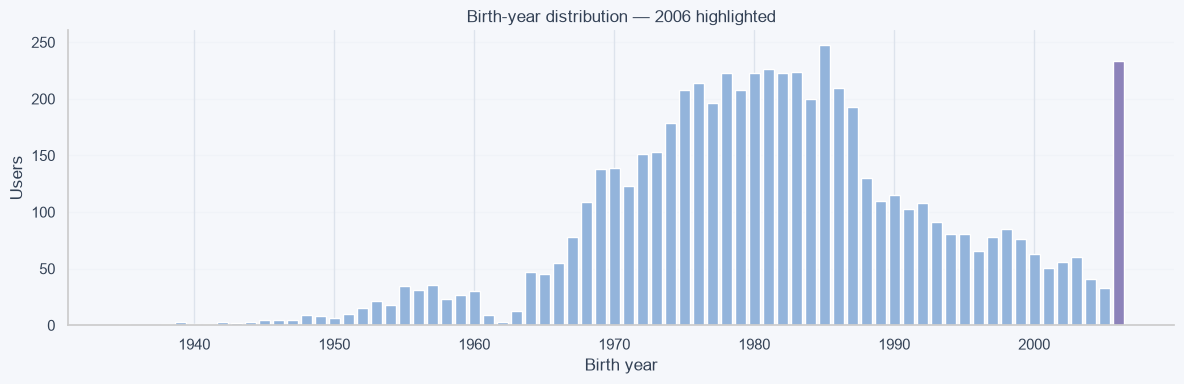

In [48]:
# subtract one year if the birthday has not yet occurred this year
# ein jahr abziehen, falls der geburtstag dieses jahr noch bevorsteht
birthdates = users_work["birthdate"]

birthday_pending = (
    (birthdates.dt.month > reference_date.month)
    | (
        (birthdates.dt.month == reference_date.month)
        & (birthdates.dt.day > reference_date.day)
    )
)

users_work["age"] = (
    reference_date.year
    - birthdates.dt.year
    - birthday_pending.astype(int)
).astype("Int64")

age_summary = pd.DataFrame({
    "metric": ["Minimum", "Median", "Mean", "Maximum"],
    "age": [
        users_work["age"].min(),
        users_work["age"].median(),
        users_work["age"].mean(),
        users_work["age"].max(),
    ],
})

display(style_overview(
    age_summary,
    "users — Age at reference date",
    {"age": "{:.1f}"},
))

birth_year_counts = (
    birthdates.dt.year
    .value_counts()
    .sort_index()
    .rename_axis("birth_year")
    .reset_index(name="users")
)

fig, ax = plt.subplots(figsize=(12, 4))
colors = [
    COLORS["highlight"] if year == 2006 else COLORS["blue"]
    for year in birth_year_counts["birth_year"]
]

ax.bar(
    birth_year_counts["birth_year"],
    birth_year_counts["users"],
    color=colors,
)
ax.set(
    title="Birth-year distribution — 2006 highlighted",
    xlabel="Birth year",
    ylabel="Users",
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

English: The 2006 birth cohort is among the most frequent in the analysis group and shows a pronounced increase compared with neighboring birth years. The cause remains unclear.
Deutsch: Der Geburtsjahrgang 2006 gehört zu den häufigsten in der Analysegruppe und zeigt einen deutlichen Anstieg gegenüber benachbarten Jahrgängen. Die Ursache ist noch unklar.

### 3.6 Investigate birth year 2006 / Geburtsjahr 2006 untersuchen

Measure the frequency of birth year 2006 and inspect its birthdates.
Repeated dates may suggest a default value, but do not establish a data error.

Die Häufigkeit des Geburtsjahrs 2006 und die einzelnen Geburtsdaten prüfen.
Wiederholte Daten könnten auf einen Standardwert hindeuten, belegen aber keinen Datenfehler.

In [49]:
# select users born in 2006
# nutzer mit geburtsjahr 2006 auswählen
users_2006 = users_work.loc[
    users_work["birthdate"].dt.year.eq(2006)
].copy()

# summarize the size and birthdate diversity of this group
# größe und anzahl unterschiedlicher geburtsdaten zusammenfassen
summary_2006 = pd.DataFrame({
    "users": [len(users_2006)],
    "share_pct": [len(users_2006) / len(users_work) * 100],
    "distinct_birthdates": [
        users_2006["birthdate"].dt.date.nunique()
    ],
})

# compare neighboring birth years
# benachbarte geburtsjahrgänge vergleichen
neighboring_years = (
    users_work["birthdate"].dt.year
    .value_counts()
    .reindex(range(2002, 2007), fill_value=0)
    .rename_axis("birth_year")
    .reset_index(name="users")
)

# identify the most frequent birthdates within 2006
# die häufigsten geburtsdaten innerhalb von 2006 ermitteln
birthdate_counts_2006 = (
    users_2006["birthdate"].dt.date
    .value_counts()
    .rename_axis("birthdate")
    .reset_index(name="users")
    .sort_values(
        ["users", "birthdate"],
        ascending=[False, True],
    )
)

# display related tables side by side using the shared design
# zusammengehörige tabellen im gemeinsamen design nebeneinander anzeigen
table_specs = [
    (
        summary_2006,
        "Birth year 2006",
        {
            "users": "{:,.0f}",
            "share_pct": "{:.2f}%",
            "distinct_birthdates": "{:,.0f}",
        },
    ),
    (
        neighboring_years,
        "Birth years 2002–2006",
        {"users": "{:,.0f}"},
    ),
    (
        birthdate_counts_2006.head(10),
        "Most frequent birthdates in 2006",
        {"users": "{:,.0f}"},
    ),
]

html_tables = [
    (
        '<div style="min-width: 0;">'
        + style_overview(df, title, formats).to_html()
        + "</div>"
    )
    for df, title, formats in table_specs
]

display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(3, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(html_tables)
    + "</div>"
))

### 3.7 Validate airport coordinates / Flughafenkoordinaten prüfen

Check coordinate ranges and whether each home airport has consistent coordinates.
Valid ranges alone do not confirm the actual airport location.

Koordinatenbereiche und die Einheitlichkeit der Koordinaten je Heimatflughafen prüfen.
Gültige Wertebereiche bestätigen allein noch nicht den tatsächlichen Flughafenstandort.

In [50]:
# check missing coordinates and valid geographic ranges
# fehlende koordinaten und gültige geografische wertebereiche prüfen
lat = users_work["home_airport_lat"]
lon = users_work["home_airport_lon"]

coordinate_checks = pd.DataFrame({
    "check": [
        "Missing latitude",
        "Missing longitude",
        "Latitude outside [-90, 90]",
        "Longitude outside [-180, 180]",
        "Both coordinates equal zero",
    ],
    "affected_users": [
        lat.isna().sum(),
        lon.isna().sum(),
        (lat.notna() & ~lat.between(-90, 90)).sum(),
        (lon.notna() & ~lon.between(-180, 180)).sum(),
        (lat.eq(0) & lon.eq(0)).sum(),
    ],
})

# count distinct coordinate pairs for each airport
# unterschiedliche koordinatenpaare je flughafen zählen
airport_pairs = users_work[
    ["home_airport", "home_airport_lat", "home_airport_lon"]
].drop_duplicates()

airport_coordinate_counts = (
    airport_pairs.groupby("home_airport")
    .size()
    .rename("coordinate_pairs")
    .reset_index()
)

inconsistent_airports = airport_coordinate_counts.loc[
    airport_coordinate_counts["coordinate_pairs"] > 1
]

table_specs = [
    (
        coordinate_checks,
        "Airport coordinate checks",
        {"affected_users": "{:,.0f}"},
    ),
    (
        inconsistent_airports,
        "Airports with multiple coordinate pairs",
        {"coordinate_pairs": "{:,.0f}"},
    ),
]

display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(2, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(
        '<div>'
        + style_overview(df, title, formats).to_html()
        + "</div>"
        for df, title, formats in table_specs
    )
    + "</div>"
))

check,affected_users
Missing latitude,0
Missing longitude,0
"Latitude outside [-90, 90]",0
"Longitude outside [-180, 180]",0
Both coordinates equal zero,0
home_airport,coordinate_pairs


**English:** Home-airport coordinates are complete, within valid ranges
and consistent per airport. Actual locations have not been externally verified.

**Deutsch:** Die Heimatflughafen-Koordinaten sind vollständig, liegen in gültigen
Bereichen und sind je Flughafen konsistent. Die tatsächlichen Standorte wurden
nicht extern überprüft.

### 3.8 Sessions before sign-up / Sessions vor der Anmeldung

Compare each user’s first session in the analysis period with their sign-up date.
If sign-up dates contain no time, compare calendar dates.

Die erste Session jedes Nutzers im Analysezeitraum mit dem Anmeldedatum vergleichen.
Wenn das Anmeldedatum keine Uhrzeit enthält, vergleichen wir Kalendertage.

In [51]:
# find each user's first session within the analysis period
# erste session je nutzer innerhalb des analysezeitraums ermitteln
first_sessions = (
    sessions_work
    .assign(
        session_start=pd.to_datetime(
            sessions_work["session_start"], errors="raise"
        )
    )
    .groupby("user_id", as_index=False)["session_start"]
    .min()
    .rename(columns={"session_start": "first_session_start"})
)

# join session dates to user profiles without modifying the source tables
# session-daten mit nutzerprofilen verbinden, ohne die quellen zu verändern
signup_check = users_work[
    ["user_id", "sign_up_date"]
].merge(
    first_sessions,
    on="user_id",
    how="left",
    validate="one_to_one",
)

signup_check["session_before_signup"] = (
    signup_check["first_session_start"].dt.normalize()
    < signup_check["sign_up_date"].dt.normalize()
)

summary = pd.DataFrame({
    "check": [
        "Users without a matching session",
        "Users with a session date before sign-up",
    ],
    "affected_users": [
        signup_check["first_session_start"].isna().sum(),
        signup_check["session_before_signup"].sum(),
    ],
})

display(style_overview(
    summary,
    "users — Session and sign-up consistency",
    {"affected_users": "{:,.0f}"},
))

# show examples only if inconsistencies exist
# beispiele nur anzeigen, falls widersprüche vorhanden sind
if signup_check["session_before_signup"].any():
    display(style_overview(
        signup_check.loc[
            signup_check["session_before_signup"],
            ["user_id", "sign_up_date", "first_session_start"],
        ].head(10),
        "Examples — Sessions before sign-up",
    ))

check,affected_users
Users without a matching session,0
Users with a session date before sign-up,0


### 3.9 Marital status and children / Familienstand und Kinder

Compare the four combinations of marital status and children.
Labels show user counts and percentages within each marital-status group.
Not married does not necessarily mean single.

Die vier Kombinationen aus Familienstand und Kinderstatus vergleichen.
Beschriftungen zeigen Nutzerzahlen und Anteile innerhalb des jeweiligen
Familienstands. Nicht verheiratet bedeutet nicht automatisch Single.

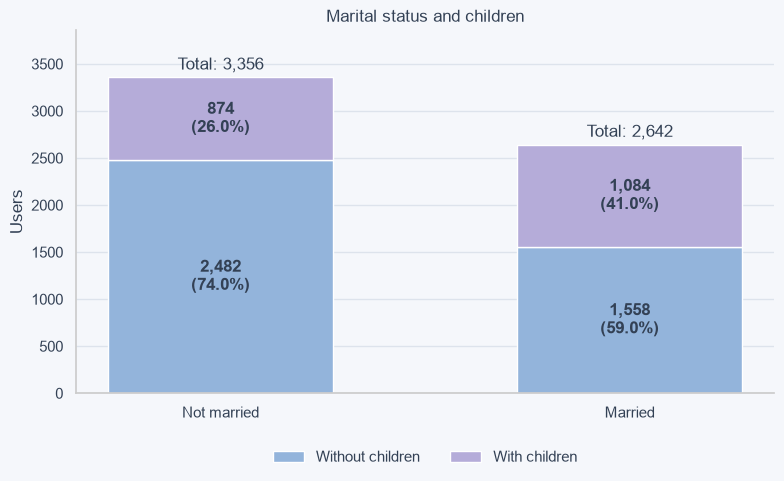

In [52]:
# count users for each combination
# nutzer je kombination zählen
family_counts = (
    pd.crosstab(users_work["married"], users_work["has_children"])
    .reindex(index=[False, True], columns=[False, True], fill_value=0)
)

family_shares = (
    family_counts
    .div(family_counts.sum(axis=1), axis=0)
    .mul(100)
)

# show all four combinations in one stacked chart
# alle vier kombinationen in einem gestapelten diagramm darstellen
fig, ax = plt.subplots(figsize=(8, 5))

positions = np.arange(len(family_counts))
bottom = np.zeros(len(family_counts))

for has_children, label, color in [
    (False, "Without children", COLORS["blue"]),
    (True, "With children", COLORS["lavender"]),
]:
    counts = family_counts[has_children].to_numpy()
    shares = family_shares[has_children].to_numpy()

    ax.bar(
        positions,
        counts,
        bottom=bottom,
        label=label,
        color=color,
        width=0.55,
    )

    for x, count, share, base in zip(positions, counts, shares, bottom):
        if count > 0:
            ax.text(
                x,
                base + count / 2,
                f"{count:,.0f}\n({share:.1f}%)",
                ha="center",
                va="center",
                color=COLORS["text"],
                fontweight="bold",
            )

    bottom += counts

# add the total number of users above each bar
# gesamtzahl der nutzer über jedem balken ergänzen
for x, total in zip(positions, bottom):
    ax.text(
        x,
        total + bottom.max() * 0.025,
        f"Total: {total:,.0f}",
        ha="center",
        color=COLORS["text"],
    )

ax.set_xticks(positions, ["Not married", "Married"])
ax.set(
    title="Marital status and children",
    ylabel="Users",
    ylim=(0, max(bottom.max(), 1) * 1.15),
)
ax.grid(axis="x", visible=False)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
)

plt.tight_layout()
plt.show()

**Findings:**
- Among 3,356 unmarried users, 874 (26.0%) have children.
- Among 2,642 married users, 1,084 (41.0%) have children.
- The share with children is about 15 percentage points higher among married users.
- These account characteristics do not establish who travels together.
- Unmarried does not necessarily mean single.

**Erkenntnisse:**
- Von 3.356 nicht verheirateten Nutzern haben 874 (26,0 %) Kinder.
- Von 2.642 verheirateten Nutzern haben 1.084 (41,0 %) Kinder.
- Der Kinderanteil liegt bei verheirateten Nutzern etwa 15 Prozentpunkte höher.
- Diese Kontomerkmale zeigen noch nicht, wer gemeinsam reist.
- Nicht verheiratet bedeutet nicht automatisch Single.

### 3.10 Gender, marital status and children
### Geschlecht, Familienstand und Kinder

Compare the share of users with and without children by gender,
separately for married and unmarried users. Each bar totals 100%.
Show group sizes; the Other category contains only 11 users overall.

Die Anteile mit und ohne Kinder nach Geschlecht vergleichen,
getrennt nach Familienstand. Jeder Balken ergibt 100 %.
Gruppengrößen anzeigen; Other umfasst insgesamt nur elf Nutzer.

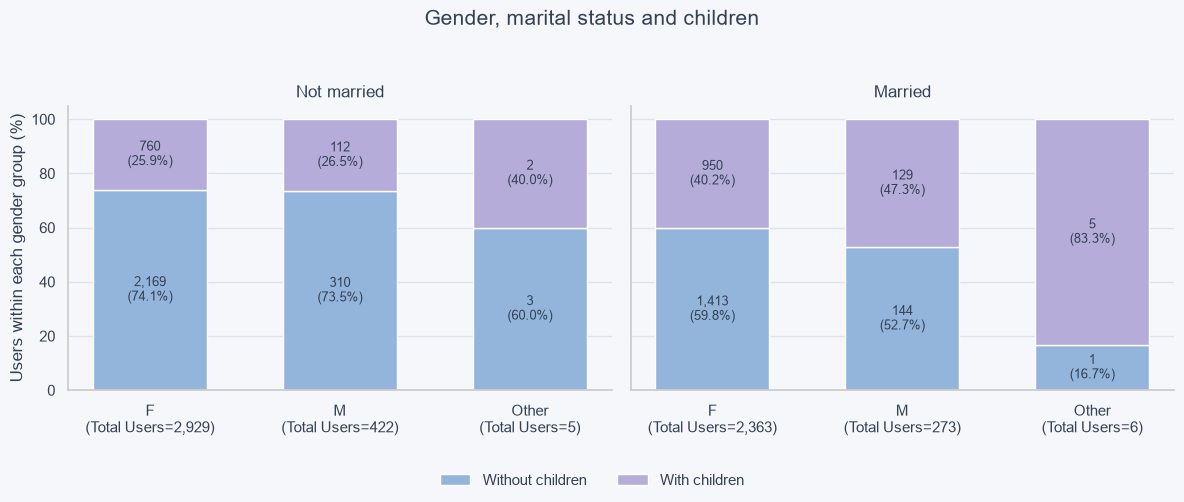

In [53]:
# compare children status by gender within each marital-status group
# kinderstatus nach geschlecht innerhalb der familienstandsgruppen vergleichen
gender_order = ["F", "M", "O"]
gender_labels = ["F", "M", "Other"]

fig, axes = plt.subplots(ncols=2, figsize=(12, 5), sharey=True)

for ax, married, title in zip(
    axes,
    [False, True],
    ["Not married", "Married"],
):
    subset = users_work.loc[users_work["married"].eq(married)]

    counts = (
        pd.crosstab(subset["gender"], subset["has_children"])
        .reindex(
            index=gender_order,
            columns=[False, True],
            fill_value=0,
        )
    )

    totals = counts.sum(axis=1)
    shares = counts.div(totals.replace(0, np.nan), axis=0).mul(100)
    bottom = np.zeros(len(gender_order))
    positions = np.arange(len(gender_order))

    for children, label, color in [
        (False, "Without children", COLORS["blue"]),
        (True, "With children", COLORS["lavender"]),
    ]:
        heights = shares[children].fillna(0).to_numpy()

        ax.bar(
            positions,
            heights,
            bottom=bottom,
            color=color,
            label=label,
            width=0.6,
        )

        for x, height, base, count in zip(
            positions, heights, bottom, counts[children]
        ):
            if height > 0:
                ax.text(
                    x,
                    base + height / 2,
                    f"{count:,.0f}\n({height:.1f}%)",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=COLORS["text"],
                )

        bottom += heights

    ax.set_xticks(
        positions,
        [
            f"{label}\n(Total Users={total:,.0f})"
            for label, total in zip(gender_labels, totals)
        ],
    )
    ax.set(title=title, ylim=(0, 105))
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Users within each gender group (%)")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
)

fig.suptitle("Gender, marital status and children", fontsize=15)
fig.tight_layout(rect=[0, 0.09, 1, 0.94])
plt.show()

**Findings:**
- Among unmarried users, the share with children is similar for women
  (25.9%) and men (26.5%).
- Among married users, 40.2% of women and 47.3% of men have children.
- For both women and men, the share with children is higher among
  married users than among unmarried users.
- The Other groups contain only five unmarried and six married users.
  Their percentages should not be generalized.
- These results describe account characteristics, not travel-party
  composition or who books on behalf of a family.

**Erkenntnisse:**
- Unter nicht verheirateten Nutzern ist der Kinderanteil bei Frauen
  (25,9 %) und Männern (26,5 %) ähnlich.
- Unter verheirateten Nutzern haben 40,2 % der Frauen und 47,3 % der Männer Kinder.
- Bei Frauen und Männern ist der Kinderanteil unter Verheirateten höher
  als unter nicht Verheirateten.
- Die Other-Gruppen umfassen nur fünf nicht verheiratete und sechs
  verheiratete Nutzer. Ihre Prozentwerte sind nicht verallgemeinerbar.
- Die Ergebnisse beschreiben Kontomerkmale, nicht die Zusammensetzung
  von Reisegruppen oder wer für eine Familie bucht.